In [1]:
#trying to recreate all the stuff in iterations_testing except with the new fitter. the point is to make sure we can implement 2DOF without too much chagrin
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [2]:
## part 1: finding the response
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2,speckle_window=70)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=60,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

In [36]:
orientation = 0
mag = np.linspace(-0.03,0.03,20)
pairs = []

for disp in mag:
    psf = PsfGen.polar_psf(magnitude=disp,orientation=orientation,num_photons=1E9,ptv=0)
    a = ADC.all_speckle_angles(psf)
    pair = ADC.speckle_pairs(a)
    pairs.append(pair)

Slope of Speckles 1&3 Response: 206.90641831256616
Slope of Speckles 2&4 Response: 98.05536428306141


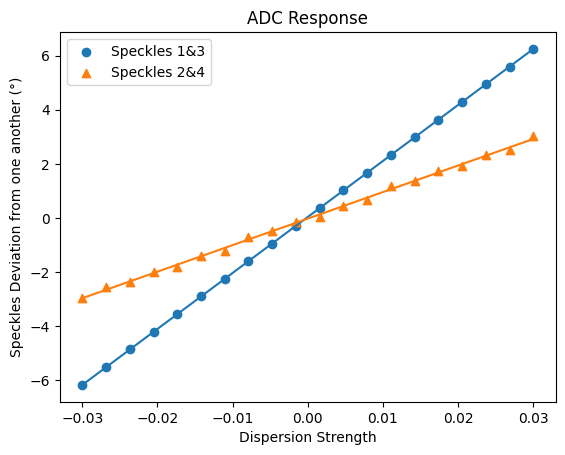

In [37]:
pairs = np.array(pairs)
a1 = np.zeros(2)
b1 = np.zeros(2)

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

for j in range(2):
    b1[j] , a1[j] = np.polyfit(mag,pairs[:,j],deg=1)
    plt.scatter(mag, pairs[:,j], label=labels[j],marker=markers[j])
    plt.plot(mag, a1[j] + b1[j] * mag)
    print(f'Slope of {labels[j]} Response: {b1[j]}')

plt.title('ADC Response')
plt.xlabel('Dispersion Strength')
plt.ylabel('Speckles Deviation from one another (°)')
plt.legend()
plt.show()

In [18]:
##now the same thing but we put a little noise and turbulence into it
orientation = 90
mag = np.linspace(-0.03,0.03,20)
noisy_pairs = []

for disp in mag:
    psf = PsfGen.polar_psf(magnitude=disp,orientation=orientation,num_photons=1E9,ptv=0.3)
    a = ADC.all_speckle_angles(psf)
    pair = ADC.speckle_pairs(a)
    noisy_pairs.append(pair)

Slope of Speckles 1&3 Response: nan
Slope of Speckles 2&4 Response: -212.5359951231276


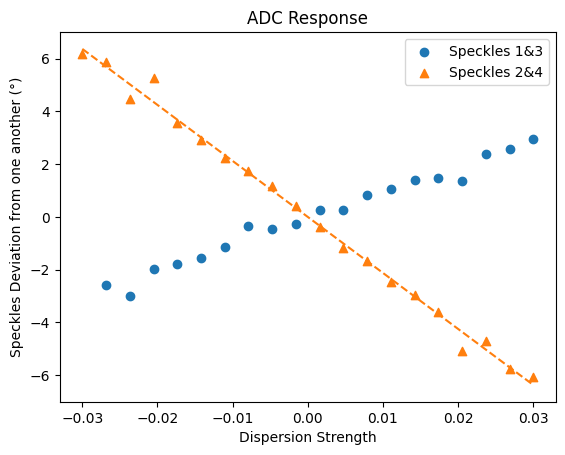

In [19]:
noisy_pairs = np.array(noisy_pairs)
a1 = np.zeros(2)
b1 = np.zeros(2)

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

for j in range(2):
    b1[j] , a1[j] = np.polyfit(mag,noisy_pairs[:,j],deg=1)
    plt.scatter(mag, noisy_pairs[:,j], label=labels[j],marker=markers[j])
    plt.plot(mag, a1[j] + b1[j] * mag,'--')
    print(f'Slope of {labels[j]} Response: {b1[j]}')

plt.title('ADC Response')
plt.xlabel('Dispersion Strength')
plt.ylabel('Speckles Deviation from one another (°)')
plt.legend()
plt.show()

In [34]:
#now looking at how the orientation affects things. keep magnitude the same but vary the orientations
orientations = np.linspace(0,90,7)
mag = 0.01
orientation_pairs = []

for angle in orientations:
    psf = PsfGen.polar_psf(magnitude=mag,orientation=angle,num_photons=1E9,ptv=0)
    a = ADC.all_speckle_angles(psf)
    pair = ADC.speckle_pairs(a)
    orientation_pairs.append(pair)

Slope of Speckles 1&3 Response: -0.01224587307097953
Slope of Speckles 2&4 Response: -0.034752794965239274


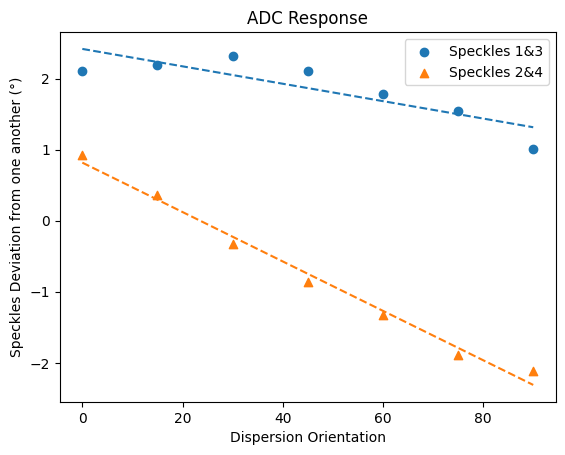

In [35]:
orientation_pairs = np.array(orientation_pairs)
a1 = np.zeros(2)
b1 = np.zeros(2)

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

for j in range(2):
    b1[j] , a1[j] = np.polyfit(orientations,orientation_pairs[:,j],deg=1)
    plt.scatter(orientations, orientation_pairs[:,j], label=labels[j],marker=markers[j])
    plt.plot(orientations, a1[j] + b1[j] * orientations,'--')
    print(f'Slope of {labels[j]} Response: {b1[j]}')

plt.title('ADC Response')
plt.xlabel('Dispersion Orientation')
plt.ylabel('Speckles Deviation from one another (°)')
plt.legend()
plt.show()